*Notebook 10 in `notebooks/arcs/`. Parameters (pre-registered): `analysis/arcs/config.yaml`; decisions and run notes: `analysis/arcs/LOG.md`. The static page `site/arcs/index.html` is built from the same saved outputs.*

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]   # notebooks/arcs -> repo root
sys.path.insert(0, str(REPO))

import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, display

from analysis.static_figures import use_static_figures

from analysis.arcs import s10_checks as step

use_static_figures()   # figures become static PNGs (they show on GitHub); interactive ones are on the static page
warnings.filterwarnings("ignore", category=RuntimeWarning)   # known 0/0 on very short arcs, handled downstream
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## Step 10 · Franchise, transcript and leakage checks

**Why.** The earlier word-level branch found a weak signal that vanished once franchise films were removed.
That is the reason the primary sample here excludes likely franchise films. Removing them changes two things
at once, though: *which* films are in the sample and *how many*. This step separates the two:
- **(a)** all arc-ready scripts, franchise films included;
- **(b)** the primary sample, likely franchise films excluded;
- **(c)** the primary sample also without the possible transcripts, which have little description;
- **(d)** all scripts minus the same number of **randomly chosen non-franchise** films, 50 times.

If (b) differs from (a) only because it has fewer films, the random drops in (d) should look like (b). If
the franchise films themselves matter, (d) should look like (a).

**Leakage.** Screenplays are written before release, so a film's success cannot have shaped its script. That
is an advantage over reviews and ratings, which come after. We assume each MovieSum script is the final
shooting draft. We can't verify that from the data; the script sheet of Step 4 checks a sample by hand.

These rows use the same statistic as Step 7. Only (b) repeats the primary sample; the rest is exploratory.

In [2]:
res = step.run()   # recomputes this step and saves its outputs

**Table.** The Step 7 statistic on samples (a), (b) and (c).

In [3]:
display(step.tables(res)["checks"])

,sample,descriptor,N,franchise films,rho,95% CI,z,p
0,"(a) all scripts, franchise included",D1,1043,209,0.046,"[-0.017, +0.118]",1.376,0.150
1,"(a) all scripts, franchise included",D2,1043,209,0.059,"[+0.000, +0.110]",2.038,0.048
2,(b) primary: likely franchise excluded,D1,834,0,0.035,"[-0.024, +0.107]",0.999,0.281
3,(b) primary: likely franchise excluded,D2,834,0,0.078,"[+0.015, +0.146]",2.053,0.036
4,(c) primary without possible transcripts,D1,825,0,0.033,"[-0.030, +0.097]",0.887,0.373
5,(c) primary without possible transcripts,D2,825,0,0.075,"[+0.013, +0.143]",2.031,0.040


**Table.** Random drops (d) against (a) and (b).

In [4]:
display(step.tables(res)["drops"])

,descriptor,ρ (a) all scripts,ρ (b) franchise excluded,"ρ (d) random drops, median",(d) 5th–95th percentile,share of drops at least as far from (a) as (b) is,drops with p < 0.05
0,D1,0.046,0.035,0.049,"[+0.021, +0.069]",0.26,6 of 50
1,D2,0.059,0.078,0.054,"[+0.025, +0.082]",0.10,9 of 50


**Figure.** D1: ρ over 50 random drops (grey), with (a) all scripts and (b) franchise excluded marked.

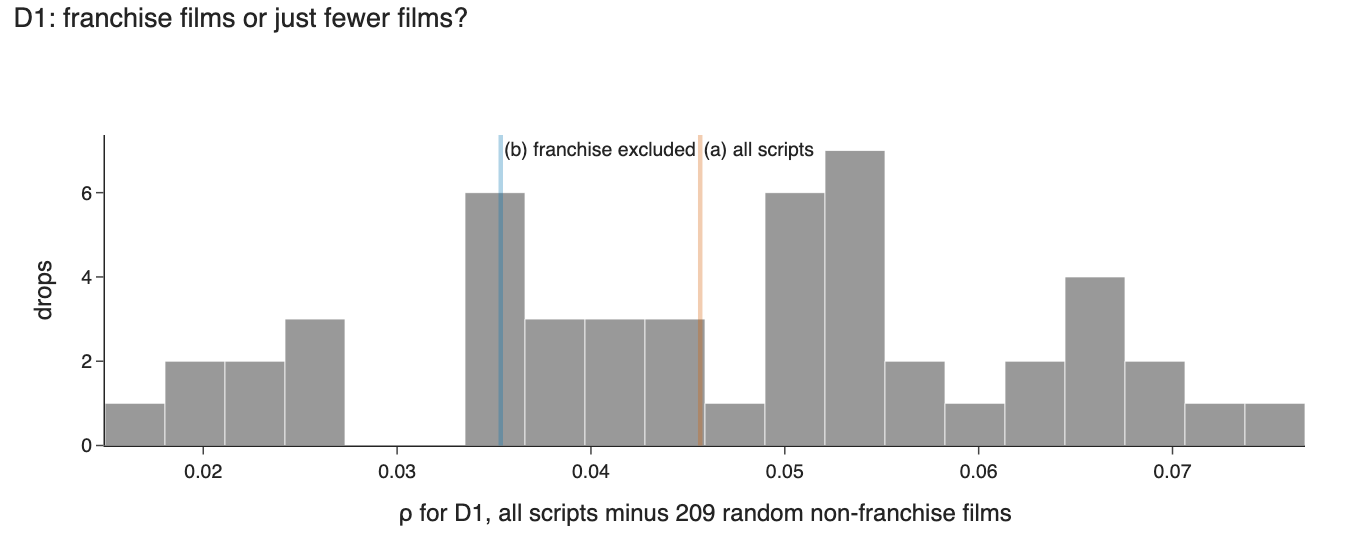

In [5]:
step.figures(res)["drops_D1"].show()

**Figure.** D2: the same.

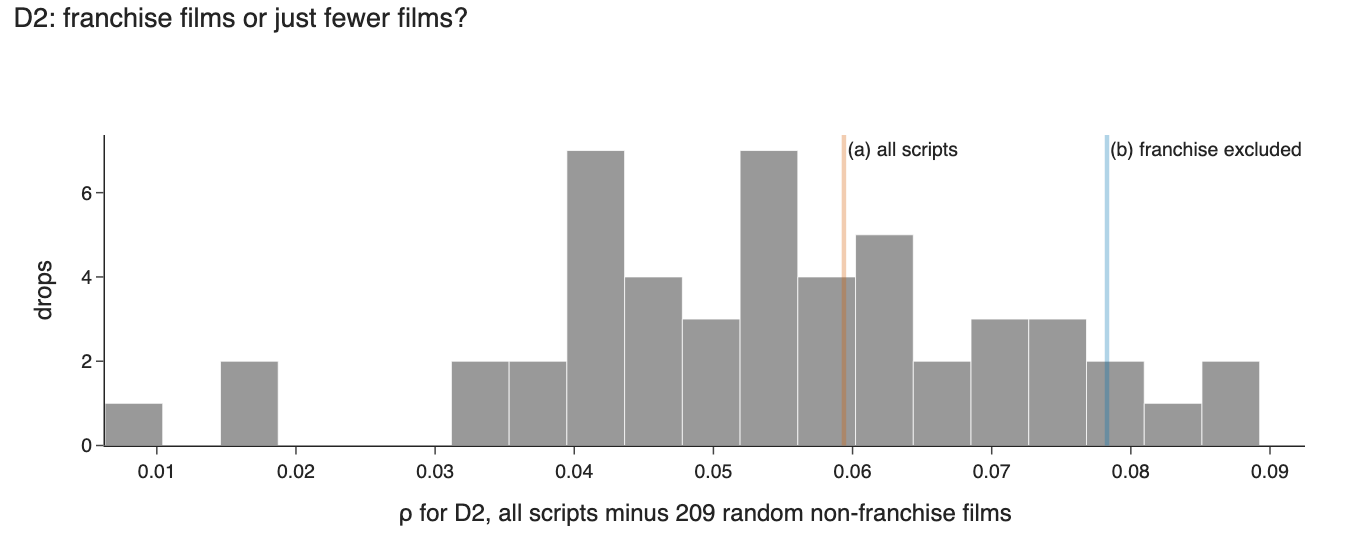

In [6]:
step.figures(res)["drops_D2"].show()

**Plain-language reading** (generated from the saved numbers):

In [7]:
display(Markdown(step.reading(res)))

For volatility (D1): ρ = +0.046 with all scripts, +0.035 without likely franchise films and +0.033 also without possible transcripts. Dropping the same number of random non-franchise films instead gives a median ρ of +0.049 (5th–95th percentile +0.021 to +0.069). (a) and (b) barely differ (Δρ = -0.010), so there is little for the franchise films to explain. The franchise-free value lies inside that range, so the difference between (a) and (b) is what losing that many films does anyway, not something franchise films carry. For ending minus start (D2): ρ = +0.059 with all scripts, +0.078 without likely franchise films and +0.075 also without possible transcripts. Dropping the same number of random non-franchise films instead gives a median ρ of +0.054 (5th–95th percentile +0.025 to +0.082). (a) and (b) barely differ (Δρ = +0.019), so there is little for the franchise films to explain. The franchise-free value lies inside that range, so the difference between (a) and (b) is what losing that many films does anyway, not something franchise films carry. Leakage: the scripts were written before release, so a film's success cannot have shaped its script. That is an advantage over reviews and ratings. That each MovieSum script is the final shooting draft is an unverified assumption (Step 4's script sheet checks a sample).